# 01 – Làm sạch dữ liệu Online Retail
Quy trình trong notebook: **xem dữ liệu → nhận xét → đề xuất phương án → xử lý → lưu dữ liệu sạch**.
**Các bước xử lý:** điền Description thiếu → bỏ dòng trùng → lọc giao dịch hợp lệ (bỏ hóa đơn hủy, `Quantity > 0`, `Price > 0`, bỏ mã hàng đặc biệt) → bỏ ngoại lai cực đoan → điền Customer ID thiếu = "Guest". Kèm chuẩn hóa văn bản và đổi `EIRE → Ireland`. 

## 1. Import thư viện và đọc dữ liệu

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 11})


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
sys.path.insert(0, str(ROOT / "src"))
import preprocessing as pp
print("Thư mục gốc:", ROOT)

Raw có **1 sheet**. 

In [ ]:
PATH = ROOT / "data" / "raw" / "Online Retail.xlsx"

sha = pp.sha256_of(PATH)
print("SHA-256:", sha)
assert sha == pp.RAW_SHA256, "Raw không phải file raw của dự án!"

df = pp.load_raw(PATH)          
print("shape:", df.shape)
df.head()

SHA-256: 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d


shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,17850.000,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,17850.000,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,17850.000,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,17850.000,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,17850.000,United Kingdom


## 2. Xem tổng quan dữ liệu

### 2.1. Kích thước, kiểu dữ liệu

In [ ]:
print("shape:", df.shape)
print("size :", df.size)
print("Bộ nhớ: %.1f MB" % (df.memory_usage(deep=True).sum() / 1024**2))
df.info()

shape: (541909, 8)
size : 4335272


Bộ nhớ: 126.2 MB


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


### 2.2. Thống kê mô tả

In [ ]:

display(df[["Quantity", "UnitPrice"]].describe(percentiles=[.01, .25, .5, .75, .99]).T)

,count,mean,std,min,1%,25%,50%,75%,99%,max
Quantity,541909.000,9.552,218.081,-80995.000,-2.000,1.000,3.000,10.000,100.000,80995.000
UnitPrice,541909.000,4.611,96.760,-11062.060,0.190,1.250,2.080,4.130,18.000,38970.000


In [ ]:

display(df.select_dtypes(exclude=["number", "datetime"]).describe().T)
display(df[["InvoiceDate"]].describe().T)

,count,unique,top,freq
InvoiceNo,541909,25900,573585,1114
StockCode,541909,4070,85123A,2313
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369
Country,541909,38,United Kingdom,495478


,count,mean,min,25%,50%,75%,max
InvoiceDate,541909,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00


### 2.3. Độ lệch (skew) và tứ phân vị

In [ ]:
rows = []
for col in ["Quantity", "UnitPrice"]:
    s = df[col]; q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    rows.append({"Cột": col, "Skew": s.skew(), "Kurtosis": s.kurt(), "Q1": q1, "Median": s.median(),
                 "Q3": q3, "IQR": iqr, "Hàng rào dưới": q1 - 1.5 * iqr, "Hàng rào trên": q3 + 1.5 * iqr,
                 "Min": s.min(), "Max": s.max()})
display(pd.DataFrame(rows).set_index("Cột").T)

Cột,Quantity,UnitPrice
Skew,-0.264,186.507
Kurtosis,119769.160,59005.719
Q1,1.000,1.250
Median,3.000,2.080
Q3,10.000,4.130
IQR,9.000,2.880
Hàng rào dưới,-12.500,-3.070
Hàng rào trên,23.500,8.450
Min,-80995.000,-11062.060
Max,80995.000,38970.000


### 2.4. Số lượng giá trị duy nhất

In [ ]:
print("Số hóa đơn      :", df["InvoiceNo"].nunique())
print("Số khách hàng   :", df["CustomerID"].nunique())
print("Số mã sản phẩm  :", df["StockCode"].nunique())
print("Số quốc gia     :", df["Country"].nunique())
print("Từ", df["InvoiceDate"].min(), "đến", df["InvoiceDate"].max())

Số hóa đơn      : 25900
Số khách hàng   : 4372
Số mã sản phẩm  : 4070
Số quốc gia     : 38
Từ 2010-12-01 08:26:00 đến 2011-12-09 12:50:00


📝 **Nhận xét phần 2:**
- Dữ liệu có **541.909 dòng × 8 cột**, mỗi dòng là *một mặt hàng trên một hóa đơn* (không phải một khách hàng hay một hóa đơn). `InvoiceDate` đã là datetime nên không cần convert. `CustomerID` đang là `float64` vì có NaN, sau khi xử lý thiếu sẽ đổi sang chuỗi.
- **Mean ≫ median** ở cả hai cột: `Quantity` trung bình ~9,6 còn trung vị là 3; `UnitPrice` trung bình ~4,6 còn trung vị ~2,1. Kurtosis cực lớn và `Max` cách Q3 hàng nghìn lần → phân phối **đuôi rất dài**.
- **Min/max lạ:** `Quantity` từ -80.995 đến +80.995; `UnitPrice` tối đa 38.970. Skew của `Quantity` gần 0 (≈ -0,26) **không có nghĩa là phân phối cân đối**, chỉ vì hai điểm cực trị âm/dương gần bằng nhau triệt tiêu; còn `UnitPrice` lệch phải cực mạnh (skew ≈ 186). Chưa nên đọc độ lệch khi chưa loại các lỗi nghiệp vụ.
- Có **4.372 khách** có ID, 25.900 hóa đơn, 4.070 mã hàng, 38 quốc gia; dữ liệu từ 01/12/2010 đến 09/12/2011 (chưa tròn một năm).

## 3. Kiểm tra chất lượng dữ liệu

### 3.1. Dữ liệu thiếu

In [ ]:
missing = pd.DataFrame({
    "Số thiếu": df.isnull().sum(),
    "Tỷ lệ (%)": (df.isnull().sum() / len(df) * 100).round(2),
})
display(missing)

is_c = df["InvoiceNo"].astype(str).str.startswith("C")
print("Thiếu CustomerID trong hóa đơn hủy   :", f"{df.loc[is_c, 'CustomerID'].isna().mean():.1%}")
print("Thiếu CustomerID trong hóa đơn thường:", f"{df.loc[~is_c, 'CustomerID'].isna().mean():.1%}")
miss_desc = df[df["Description"].isna()]
print("Dòng thiếu Description:", len(miss_desc),
      "| trong đó UnitPrice == 0:", int((miss_desc["UnitPrice"] == 0).sum()),
      "| trong đó có CustomerID:", int(miss_desc["CustomerID"].notna().sum()),
      "| tổng Quantity×UnitPrice:", float((miss_desc["Quantity"] * miss_desc["UnitPrice"]).sum()))

,Số thiếu,Tỷ lệ (%)
InvoiceNo,0,0.000
StockCode,0,0.000
Description,1454,0.270
Quantity,0,0.000
InvoiceDate,0,0.000
UnitPrice,0,0.000
CustomerID,135080,24.930
Country,0,0.000


Thiếu CustomerID trong hóa đơn hủy   : 4.1%
Thiếu CustomerID trong hóa đơn thường: 25.3%
Dòng thiếu Description: 1454 | trong đó UnitPrice == 0: 1454 | trong đó có CustomerID: 0 | tổng Quantity×UnitPrice: 0.0


### 3.2. Dòng trùng lặp

In [ ]:
dup = df.duplicated()
print("Số dòng trùng hoàn toàn (giữ bản đầu tiên):", int(dup.sum()), f"({dup.mean():.2%})")
print("Số hóa đơn có dòng trùng:", df.loc[dup, "InvoiceNo"].nunique())
display(df[df.duplicated(keep=False)].sort_values(["InvoiceNo", "StockCode"]).head(6))

Số dòng trùng hoàn toàn (giữ bản đầu tiên): 5268 (0.97%)
Số hóa đơn có dòng trùng: 1933


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.250,17908.000,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.250,17908.000,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.950,17908.000,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.950,17908.000,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.100,17908.000,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.100,17908.000,United Kingdom


### 3.3. Hóa đơn hủy, Quantity và Price không hợp lệ

In [ ]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
cancelled = df["InvoiceNo"].str.startswith("C")

print("Dòng thuộc hóa đơn hủy (bắt đầu bằng C):", cancelled.sum())
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("  trong đó KHÔNG phải hóa đơn hủy:", ((df["Quantity"] <= 0) & ~cancelled).sum())
print("Hóa đơn hủy mà Quantity > 0:", (cancelled & (df["Quantity"] > 0)).sum())
print("UnitPrice == 0:", (df["UnitPrice"] == 0).sum())
print("UnitPrice < 0 :", (df["UnitPrice"] < 0).sum())
display(df[df["UnitPrice"] < 0][["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]])
display(df[(df["Quantity"] <= 0) & ~cancelled]["Description"].value_counts(dropna=False).head(6).to_frame("số dòng"))

Dòng thuộc hóa đơn hủy (bắt đầu bằng C): 9288
Quantity <= 0: 10624
  trong đó KHÔNG phải hóa đơn hủy: 1336
Hóa đơn hủy mà Quantity > 0: 0
UnitPrice == 0: 2515
UnitPrice < 0 : 2


,InvoiceNo,StockCode,Description,Quantity,UnitPrice
299983,A563186,B,Adjust bad debt,1,-11062.060
299984,A563187,B,Adjust bad debt,1,-11062.060


,số dòng
Description,
NaN,862
check,120
damages,45
damaged,42
?,41
sold as set on dotcom,20


### 3.4. Mã sản phẩm không phải hàng hóa (bưu phí, phí ngân hàng...)

In [ ]:
df["StockCode"] = df["StockCode"].astype(str)
is_product = df["StockCode"].str.match(r"^\d{5}[A-Za-z]*$")

print("Số dòng có StockCode lạ:", (~is_product).sum())
odd = df.loc[~is_product].assign(StockCode=lambda d: d["StockCode"].str.upper())
display(odd.groupby("StockCode").agg(số_dòng=("InvoiceNo", "size"), giá_TB=("UnitPrice", "mean"),
        mô_tả=("Description", lambda s: s.dropna().iloc[0] if s.notna().any() else None))
        .sort_values("số_dòng", ascending=False).head(15))

Số dòng có StockCode lạ: 2995


,số_dòng,giá_TB,mô_tả
StockCode,,,
POST,1256,36.933,POSTAGE
DOT,710,290.496,DOTCOM POSTAGE
M,572,374.914,Manual
C2,144,49.292,CARRIAGE
D,77,72.485,Discount
S,63,50.405,SAMPLES
BANK CHARGES,37,202.855,Bank Charges
AMAZONFEE,34,7324.785,AMAZON FEE
CRUK,16,495.839,CRUK Commission


📝 **Nhận xét phần 3:**
- **CustomerID thiếu nhiều nhất: 135.080 dòng (~24,9%)**; Description thiếu 1.454 dòng (~0,3%). Điểm đáng chú ý: **cả 1.454 dòng thiếu Description đều có `UnitPrice = 0` và không có CustomerID**, nên giá trị giao dịch của chúng bằng 0. CustomerID thiếu chủ yếu nằm ở hóa đơn thường (~25%), hóa đơn hủy thiếu ít hơn (~4%).
- **5.268 dòng trùng hoàn toàn (~1%)**: cùng hóa đơn, mã hàng, số lượng, giá và giờ-phút. Giữ lại sẽ nhân đôi số lượng và giá trị mua.
- **Hóa đơn hủy (tiền tố C) có 9.288 dòng và đều có Quantity âm.** Tổng Quantity ≤ 0 là 10.624 dòng, nghĩa là còn **1.336 dòng Quantity âm mà không có tiền tố C**: phần lớn không có mô tả (862 dòng) hoặc ghi `check`, `damages`, `?`… → bút toán kho, không phải mua bán. Vì vậy phải lọc bằng `Quantity > 0`, không chỉ bỏ hóa đơn có chữ C.
- `UnitPrice = 0` có 2.515 dòng (tặng/điều chỉnh/lỗi) và `UnitPrice < 0` có 2 dòng (điều chỉnh sổ sách, xem bảng trên).
- Các **StockCode lạ** như `POST`, `DOT`, `M`, `C2`, `D`, `S`, `BANK CHARGES`, `AMAZONFEE`, `CRUK` là phí/bưu phí/chiết khấu/mẫu, giá trung bình rất cao so với hàng thường (hàng chục đến hàng nghìn bảng; `AMAZONFEE` trung bình trên 7.000 £). Nếu giữ sẽ làm **tổng tiền của khách bị sai lệch**.

## 4. Vẽ hình để xem dữ liệu

### 4.1. Histogram – xem dữ liệu có lệch không

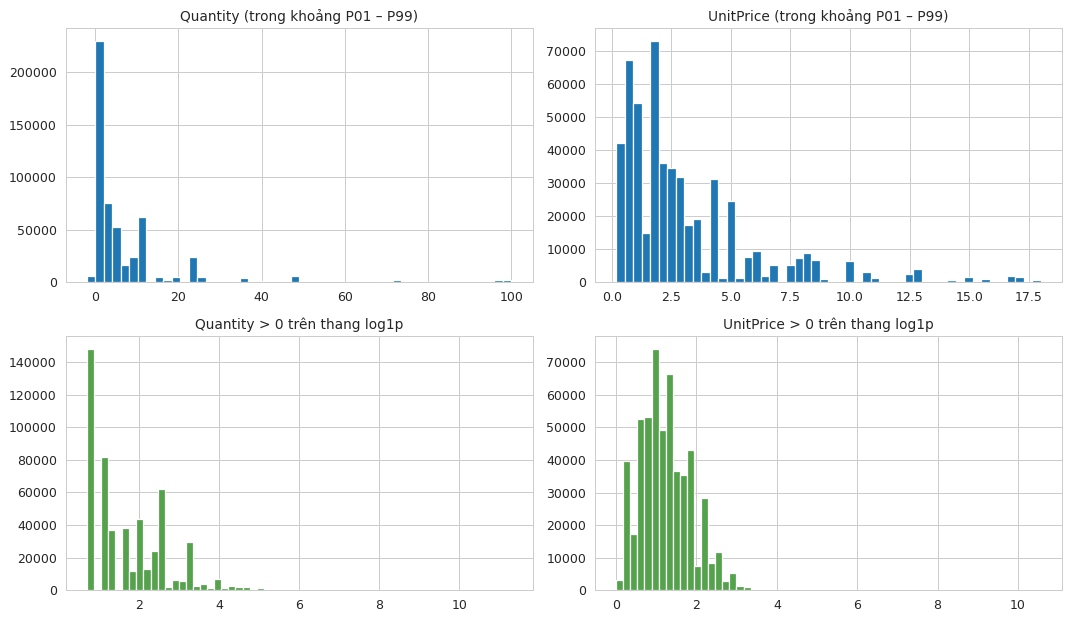

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for j, col in enumerate(["Quantity", "UnitPrice"]):
    low, high = df[col].quantile([0.01, 0.99])
    df.loc[df[col].between(low, high), col].hist(bins=50, ax=axes[0, j])
    axes[0, j].set_title(f"{col} (trong khoảng P01 – P99)")
    pos = df.loc[df[col] > 0, col]
    axes[1, j].hist(np.log1p(pos), bins=60, color="#54A24B")
    axes[1, j].set_title(f"{col} > 0 trên thang log1p")
plt.tight_layout(); plt.show()

### 4.2. Boxplot – xem có ngoại lai không

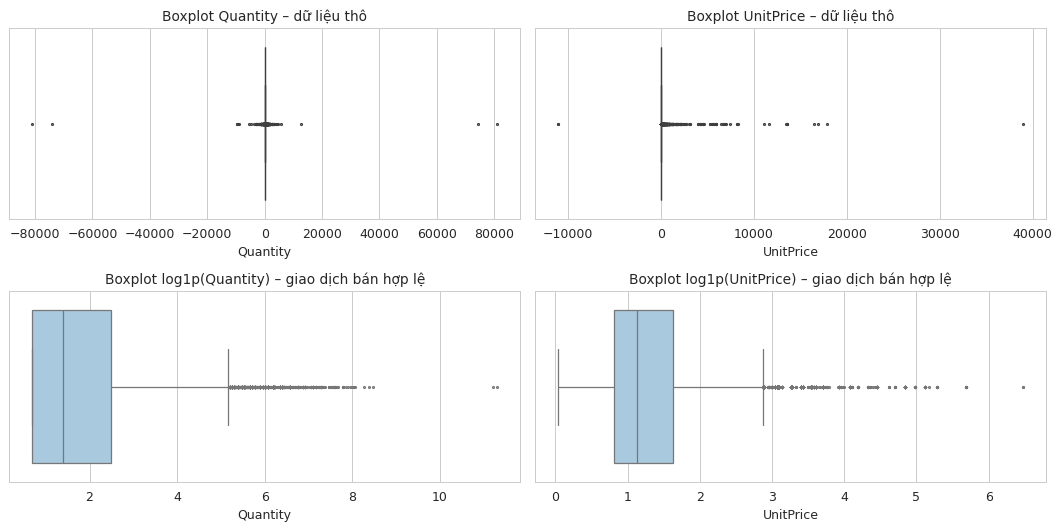

In [ ]:
valid = df[~cancelled & (df["Quantity"] > 0) & (df["UnitPrice"] > 0) & is_product].copy()   # giao dịch bán hợp lệ, để xem ngoại lai thật

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for j, col in enumerate(["Quantity", "UnitPrice"]):
    sns.boxplot(x=df[col], ax=axes[0, j], fliersize=1.5); axes[0, j].set_title(f"Boxplot {col} – dữ liệu thô")
    sns.boxplot(x=np.log1p(valid[col]), ax=axes[1, j], fliersize=1.5, color="#A0CBE8")
    axes[1, j].set_title(f"Boxplot log1p({col}) – giao dịch bán hợp lệ")
plt.tight_layout(); plt.show()

### 4.3. Countplot – quốc gia và khách có/không có ID

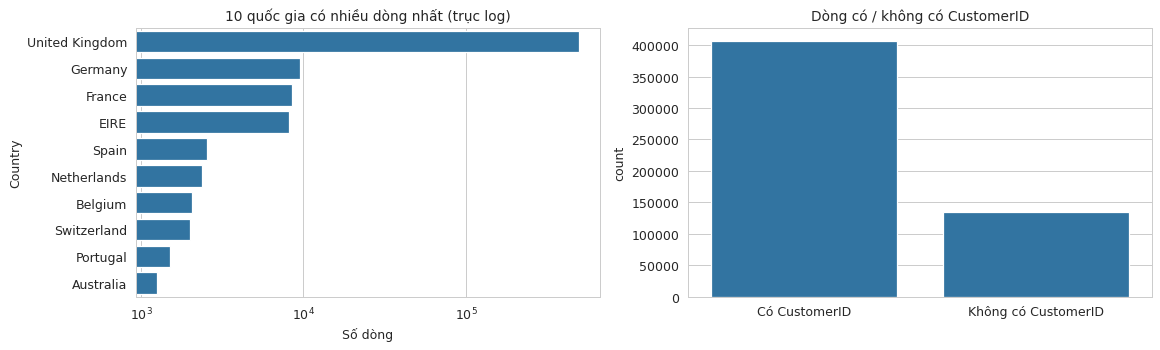

Tỷ trọng United Kingdom: 91.4% | 'EIRE': 8196 | 'Ireland': 0


In [ ]:
top_country = df["Country"].value_counts().head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=top_country.values, y=top_country.index, ax=axes[0])
axes[0].set_xscale("log"); axes[0].set_title("10 quốc gia có nhiều dòng nhất (trục log)"); axes[0].set_xlabel("Số dòng")
guest = df["CustomerID"].isna().map({True: "Không có CustomerID", False: "Có CustomerID"})
sns.countplot(x=guest, ax=axes[1]); axes[1].set_title("Dòng có / không có CustomerID"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
print("Tỷ trọng United Kingdom:", f"{(df['Country'] == 'United Kingdom').mean():.1%}", "| 'EIRE':", int((df['Country'] == 'EIRE').sum()), "| 'Ireland':", int((df['Country'] == 'Ireland').sum()))

### 4.4. Chọn ngưỡng ngoại lai: IQR × 1,5 hay × 3?

,Dòng bị loại,% dòng,% doanh thu bị mất,Khách mất hoàn toàn,Chi tiêu 50 khách lớn nhất còn lại (%)
Hệ số IQR,,,,,
1.500,7242,1.372,16.955,36,56.878
3.000,191,0.036,3.344,7,89.504


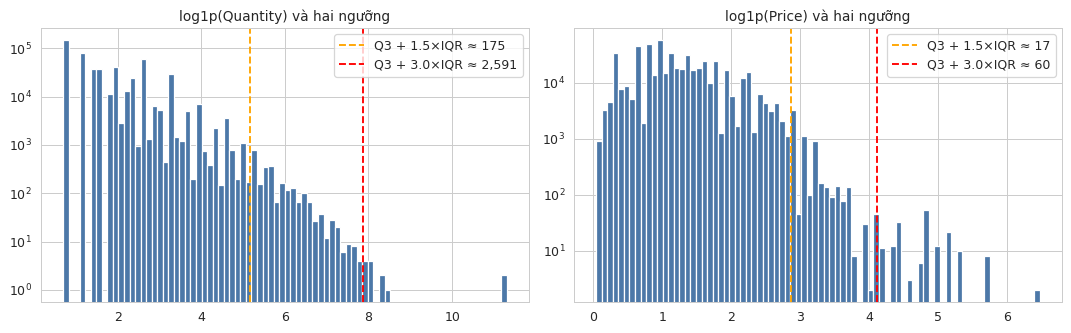

In [ ]:
reg = valid.rename(columns=pp.RENAME)                 # đổi sang tên cột dùng trong pipeline (Price, Customer ID)
reg["Revenue"] = reg["Quantity"] * reg["Price"]
cust_spend = reg[reg["Customer ID"].notna()].groupby("Customer ID")["Revenue"].sum()
top50 = cust_spend.nlargest(50).index

def impact(k):
    mask = pp.outlier_mask(reg, k=k)
    kept = reg[~mask]
    kept_spend = kept[kept["Customer ID"].notna()].groupby("Customer ID")["Revenue"].sum()
    return {"Hệ số IQR": k, "Dòng bị loại": int(mask.sum()), "% dòng": 100 * mask.mean(),
            "% doanh thu bị mất": 100 * reg.loc[mask, "Revenue"].sum() / reg["Revenue"].sum(),
            "Khách mất hoàn toàn": len(set(cust_spend.index) - set(kept_spend.index)),
            "Chi tiêu 50 khách lớn nhất còn lại (%)": 100 * kept_spend.reindex(top50).fillna(0).sum() / cust_spend[top50].sum()}

display(pd.DataFrame([impact(1.5), impact(3.0)]).set_index("Hệ số IQR"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col in zip(axes, ["Quantity", "Price"]):
    x = np.log1p(reg[col]); q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    ax.hist(x, bins=80, color="#4C78A8")
    for k, c in [(1.5, "orange"), (3.0, "red")]:
        ax.axvline(q3 + k * iqr, color=c, ls="--", label=f"Q3 + {k}×IQR ≈ {np.expm1(q3 + k * iqr):,.0f}")
    ax.set_yscale("log"); ax.set_title(f"log1p({col}) và hai ngưỡng"); ax.legend()
plt.tight_layout(); plt.show()

📝 **Nhận xét phần 4:**
- **Histogram:** cả `Quantity` và `UnitPrice` lệch **phải** rất mạnh (thân dồn về giá trị nhỏ, đuôi kéo dài); sau `log1p` histogram gần dạng chuông → dữ liệu gần log-normal, nên xét ngoại lai trên thang log.
- **Boxplot:** trên dữ liệu thô boxplot bị ép dẹt vì vài điểm quá lớn (±80.995 cái, giá tới 38.970); sau khi bỏ lỗi nghiệp vụ và lấy log vẫn còn nhiều điểm ngoài râu. Những điểm đó **không toàn là lỗi**: nhiều đơn là khách **mua sỉ thật** (12, 24, 144 cái/mã); chỉ vài điểm cực đoan như 80.995 và 74.215 cái là đơn nhập nhầm rồi bị hủy.
- **Quốc gia:** United Kingdom chiếm ~91% số dòng; còn lại nhỏ lẻ. Giá trị `EIRE` (8.196 dòng) thực chất là Ireland và chưa có nhãn `Ireland` nào, nên đổi tên cho nhất quán. Tỷ lệ dòng không có CustomerID là ~25%.
- **Ngưỡng ngoại lai:** cắt theo **IQR × 1,5** chỉ mất ~1,4% số dòng nhưng làm mất **~17% doanh thu**, 36 khách biến mất hoàn toàn và 50 khách chi tiêu lớn nhất mất hơn 40% chi tiêu — đây chính là nhóm khách giá trị cao mà đề tài muốn tìm. Cắt theo **IQR × 3** chỉ mất ~0,04% số dòng (~3% doanh thu), còn giữ khoảng 90% chi tiêu của 50 khách lớn nhất → chọn **IQR × 3 trên log1p**. (Số dòng ở mục này tính trước khi bỏ trùng nên hơi nhiều hơn số thực tế ở Bước 4.)

## 5. Đề xuất phương án xử lý

Số dòng của từng vấn đề được tính ở cell code ngay bên dưới bảng; bảng nêu phương án đề xuất và lý do.

| Vấn đề | Phương án đề xuất | Lý do |
|---|---|---|
| Thiếu Description | Điền `"Unknown Product"` | Không mất dòng và không mất doanh thu. **Lưu ý:** cả các dòng này đều có `UnitPrice = 0` và không có CustomerID nên vẫn sẽ bị loại ở bước lọc `Price > 0` |
| Dòng trùng | Loại bỏ (`drop_duplicates`) | Bản sao do ghi lặp, giữ lại sẽ nhân đôi Frequency và Monetary |
| Hóa đơn hủy (C) | Loại bỏ khỏi dữ liệu | Để tính doanh thu từ đơn thành công, không để tiền âm triệt tiêu doanh thu |
| `Quantity <= 0` | Loại bỏ | Gồm hóa đơn hủy và bút toán kho (`check`, `damages`, dòng không có mô tả), không phải giao dịch mua |
| `UnitPrice <= 0` | Loại bỏ | Hàng tặng/điều chỉnh, không tạo doanh thu |
| StockCode không phải hàng hóa | Loại bỏ toàn bộ danh sách mã dịch vụ | Phí/chiết khấu làm lệch doanh thu từng khách. Danh sách gồm `POST`, `D`, `M`, `BANK CHARGES`, `DOT`, `C2`, `S`, `AMAZONFEE`, `CRUK`... |
| Ngoại lai Quantity, Price | Loại bỏ **ngoại lai cực đoan**: ngoài Q1 − 3×IQR, Q3 + 3×IQR trên `log1p` | Dữ liệu log-normal; IQR × 1,5 mất ~17% doanh thu và cắt khách lớn (mục 4.4); chọn ngưỡng nhẹ để không xóa khách mua sỉ thật |
| Thiếu CustomerID | Điền `"Guest"`, thêm cột cờ `IsGuest` | Giữ doanh thu của khách vãng lai và phân biệt khách có ID/khách lẻ. **Khi tính RFM phải bỏ `Guest`**, vì nó gộp nhiều người mua khác nhau thành một "khách" khổng lồ |
| `EIRE`, khoảng trắng, chữ hoa/thường | Đổi `EIRE → Ireland`, `strip`, viết hoa Description | Cùng một giá trị phải có cùng một cách viết (làm trước bước bỏ trùng để bắt được trùng do khác khoảng trắng) |
| Kiểu dữ liệu `CustomerID` | Đổi sang chuỗi sau khi điền thiếu | Cột có cả số lẫn `"Guest"` nên không thể là số nguyên |
| Tên cột | Đổi `InvoiceNo → Invoice`, `UnitPrice → Price`, `CustomerID → Customer ID` | Khớp tên cột đang dùng trong `src/features.py` |

In [ ]:
sc = df["StockCode"].str.strip().str.upper()
summary = pd.DataFrame({"Số dòng": {
    "Thiếu CustomerID": int(df["CustomerID"].isna().sum()),
    "Thiếu Description": int(df["Description"].isna().sum()),
    "Dòng trùng": int(df.duplicated().sum()),
    "Hóa đơn hủy (InvoiceNo bắt đầu bằng C)": int(cancelled.sum()),
    "Quantity <= 0": int((df["Quantity"] <= 0).sum()),
    "UnitPrice <= 0": int((df["UnitPrice"] <= 0).sum()),
    "StockCode đặc biệt (trong danh sách loại)": int(sc.isin(pp.SPECIAL_CODES).sum()),
    "Country = 'EIRE'": int((df["Country"] == "EIRE").sum()),
    "Ngoại lai cực đoan (IQR×3 trên log1p, sau khi lọc hợp lệ)": int(pp.outlier_mask(reg, k=3.0).sum()),
}})
summary["% tổng dòng"] = summary["Số dòng"] / len(df) * 100
display(summary)
print("Lưu ý: các nhóm giao nhau (ví dụ dòng hủy cũng có Quantity <= 0) nên không cộng các dòng lại với nhau.")

,Số dòng,% tổng dòng
Thiếu CustomerID,135080,24.927
Thiếu Description,1454,0.268
Dòng trùng,5268,0.972
Hóa đơn hủy (InvoiceNo bắt đầu bằng C),9288,1.714
Quantity <= 0,10624,1.960
UnitPrice <= 0,2517,0.464
StockCode đặc biệt (trong danh sách loại),2912,0.537
Country = 'EIRE',8196,1.512
"Ngoại lai cực đoan (IQR×3 trên log1p, sau khi lọc hợp lệ)",191,0.035


Lưu ý: các nhóm giao nhau (ví dụ dòng hủy cũng có Quantity <= 0) nên không cộng các dòng lại với nhau.


## 6. Xử lý dữ liệu (ghi lại số dòng sau mỗi bước)

In [ ]:
log = [("Dữ liệu gốc (Online Retail.xlsx)", len(df))]
clean = df.rename(columns=pp.RENAME).copy()     # Invoice, Price, Customer ID

### Bước 1. Điền Description thiếu + chuẩn hóa văn bản

**Làm gì:** điền `"Unknown Product"` cho Description thiếu; `strip` khoảng trắng; viết hoa Description, Invoice, StockCode; đổi `EIRE → Ireland`.

**Vì sao:** điền thay vì xóa để không làm hụt doanh thu. Trên dữ liệu này các dòng thiếu Description đều có `Price = 0` và không có CustomerID (mục 3.1) nên điền hay xóa thì **doanh thu cũng không đổi**; mình vẫn điền để dữ liệu không còn ô trống. Chuẩn hóa văn bản được làm **trước bước bỏ trùng**, vì hai dòng chỉ khác khoảng trắng hay chữ hoa mới bị phát hiện là trùng.

In [ ]:
clean["Description"] = clean["Description"].fillna("Unknown Product")
clean["Description"] = clean["Description"].astype(str).str.strip().str.upper()
clean["Invoice"] = clean["Invoice"].astype(str).str.strip().str.upper()
clean["StockCode"] = clean["StockCode"].astype(str).str.strip().str.upper()
clean["Country"] = clean["Country"].astype(str).str.strip().replace({"EIRE": "Ireland"})
log.append(("Bước 1. Điền Description thiếu, chuẩn hóa văn bản, EIRE → Ireland", len(clean)))
print("Còn thiếu Description:", clean["Description"].isna().sum(), "| 'Ireland':", (clean["Country"] == "Ireland").sum())

Còn thiếu Description: 0 | 'Ireland': 8196


### Bước 2. Loại dòng trùng lặp

**Vì sao:** một giao dịch bị ghi hai lần sẽ làm tăng ảo Frequency và Monetary của khách. Các dòng này trùng cả 8 cột, kể cả giờ-phút, nên coi là bản sao.

In [ ]:
clean = clean.drop_duplicates()
log.append(("Bước 2. Bỏ dòng trùng lặp", len(clean)))
print("Dòng còn lại:", len(clean))

Dòng còn lại: 536641


### Bước 3. Giữ giao dịch hợp lệ: bỏ hóa đơn hủy, `Quantity > 0`, `Price > 0`, mã hàng đặc biệt

**Vì sao:**
- *Hóa đơn hủy (C):* muốn doanh thu từ đơn thành công, nếu giữ thì tiền âm sẽ triệt tiêu Monetary. Đổi lại, mình **không còn thông tin hoàn trả** của khách (nếu cần có thể tách thành bảng riêng; mục đích ở đây là doanh thu nên loại bỏ).
- *`Quantity > 0` và `Price > 0`:* ngoài hóa đơn C còn có bút toán kho (`check`, `damages`, dòng không mô tả) và hàng giá 0 — không phải giao dịch mua.
- *Mã hàng đặc biệt:* `POST`, `M`, `BANK CHARGES`, `AMAZONFEE`... là phí hay chiết khấu, không phải sản phẩm.

In [ ]:
clean = clean[~clean["Invoice"].str.startswith("C")]
log.append(("Bước 3a. Bỏ hóa đơn hủy (Invoice bắt đầu bằng C)", len(clean)))

clean = clean[(clean["Quantity"] > 0) & (clean["Price"] > 0)]
log.append(("Bước 3b. Giữ Quantity > 0 và Price > 0", len(clean)))

clean = clean[~clean["StockCode"].isin(pp.SPECIAL_CODES)]
log.append(("Bước 3c. Bỏ mã hàng đặc biệt (POST, M, BANK CHARGES...)", len(clean)))
print("Dòng còn lại:", len(clean), "| còn 'Unknown Product':", int((clean["Description"] == "UNKNOWN PRODUCT").sum()))

Dòng còn lại: 522571 | còn 'Unknown Product': 0


### Bước 4. Loại ngoại lai cực đoan

**Vì sao chọn IQR × 3 trên thang `log1p`:** (xem số liệu mục 4.4)
- Dữ liệu lệch phải mạnh, nên xét ngoại lai trên thang log mới công bằng; trên thang gốc, IQR coi cả đơn sỉ hợp lệ là "ngoại lai".
- Ngưỡng 1,5 làm mất ~17% doanh thu và cắt cụt chi tiêu của khách lớn; ngưỡng 3 chỉ loại những dòng thật sự cực đoan (kiểu 80.995 cái, hoặc đơn giá hàng trăm bảng).
- Loại hết ngoại lai theo cách thông thường sẽ chỉ còn "đại đa số khách"; còn bài toán của nhóm là tìm **khách giá trị cao**, nên mình chỉ bỏ phần cực đoan và để các bước sau (log, chuẩn hóa, DBSCAN gán nhiễu) lo phần còn lại.

In [ ]:
out = pp.outlier_mask(clean)           # IQR x 3 trên log1p cho Quantity và Price
removed = clean[out]
clean = clean[~out]
log.append(("Bước 4. Bỏ ngoại lai cực đoan (IQR x 3 trên log1p)", len(clean)))
print("Dòng bị loại:", len(removed), "| của", removed["Customer ID"].nunique(), "mã khách")
display(removed.nlargest(5, "Quantity")[["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID"]])
display(removed.nlargest(3, "Price")[["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID"]])

Dòng bị loại: 183 | của 120 mã khách


,Invoice,StockCode,Description,Quantity,Price,Customer ID
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.080,16446.000
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.040,12346.000
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.210,12901.000
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.720,13135.000
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.820,18087.000


,Invoice,StockCode,Description,Quantity,Price,Customer ID
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.500,15098.000
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.500,15098.000
4989,536835,22655,VINTAGE RED KITCHEN CABINET,1,295.000,13145.000


### Bước 5. CustomerID thiếu → `"Guest"`; đổi kiểu sang chuỗi

**Vì sao:** với ~25% dòng không có mã khách, đổi thành `"Guest"` giữ lại doanh thu của khách vãng lai và phân biệt được khách có ID với khách lẻ. Cột `Customer ID` bây giờ có cả số lẫn chữ nên phải chuyển sang chuỗi.

**Cảnh báo cho bước RFM:** `"Guest"` không phải một người mà là rất nhiều người mua khác nhau. Nếu đưa vào RFM thì nó thành một "khách" có Frequency và Monetary khổng lồ, phá hỏng phân cụm. Vì vậy mình thêm cột **`IsGuest`**; khi tính RFM phải lọc `IsGuest == False`.

In [ ]:
clean["Customer ID"] = clean["Customer ID"].map(lambda v: "Guest" if pd.isna(v) else str(int(v)))
log.append(("Bước 5. Customer ID thiếu → 'Guest' (đổi kiểu sang chuỗi)", len(clean)))

clean["Revenue"] = (clean["Quantity"] * clean["Price"]).round(2)
clean["IsGuest"] = clean["Customer ID"].eq("Guest")
clean = clean.sort_values(["InvoiceDate", "Invoice"]).reset_index(drop=True)

log_df = pd.DataFrame(log, columns=["Bước", "Số dòng còn lại"])
log_df["Số dòng bị loại"] = (-log_df["Số dòng còn lại"].diff()).fillna(0).astype(int)
log_df["% còn lại so với gốc"] = (log_df["Số dòng còn lại"] / len(df) * 100).round(2)
display(log_df)

,Bước,Số dòng còn lại,Số dòng bị loại,% còn lại so với gốc
0,Dữ liệu gốc (Online Retail.xlsx),541909,0,100.000
1,"Bước 1. Điền Description thiếu, chuẩn hóa văn ...",541909,0,100.000
2,Bước 2. Bỏ dòng trùng lặp,536641,5268,99.030
3,Bước 3a. Bỏ hóa đơn hủy (Invoice bắt đầu bằng C),527390,9251,97.320
4,Bước 3b. Giữ Quantity > 0 và Price > 0,524878,2512,96.860
5,"Bước 3c. Bỏ mã hàng đặc biệt (POST, M, BANK CH...",522571,2307,96.430
6,Bước 4. Bỏ ngoại lai cực đoan (IQR x 3 trên lo...,522388,183,96.400
7,Bước 5. Customer ID thiếu → 'Guest' (đổi kiểu ...,522388,0,96.400


📝 **Nhận xét phần 6:**
- Sau khi làm sạch còn **522.388 dòng (~96,4% dữ liệu gốc)**; số khách có ID là **4.327** (cộng thêm nhãn `Guest`). Bước loại nhiều nhất là hóa đơn hủy (9.251 dòng), rồi dòng trùng (5.268), mã hàng đặc biệt (2.307) và `Quantity`/`Price` không dương (2.512).
- Ngoại lai: **loại 183 dòng cực đoan** (của khoảng 120 mã khách), gồm các đơn nhập nhầm rồi hủy như 80.995 và 74.215 cái, và vài mặt hàng giá rất cao (ví dụ giỏ picnic 649,5 £). Phần còn lại giữ nguyên vì đa số là đơn sỉ hợp lệ của nhóm khách giá trị cao. Skew vẫn còn lớn trên thang gốc nên ở bước RFM cần log trước khi chuẩn hóa.
- `Guest` chiếm ~25% số dòng; **phải lọc ra** khi tính RFM (xem Bước 5).

## 7. Kiểm tra lại và lưu dữ liệu sạch

In [ ]:

c2, l2 = pp.clean_data(df)
assert c2.shape == clean.shape and np.isclose(c2["Revenue"].sum(), clean["Revenue"].sum())
assert clean.isnull().sum().sum() == 0
assert (clean["Quantity"] > 0).all() and (clean["Price"] > 0).all()
assert not clean["Invoice"].str.startswith("C").any() and not clean["StockCode"].isin(pp.SPECIAL_CODES).any()
assert not clean.duplicated().any()
print("Các kiểm tra hợp lệ.\n")

print("shape:", clean.shape)
print("Số khách hàng có ID:", clean.loc[~clean["IsGuest"], "Customer ID"].nunique(), "| dòng Guest:", int(clean["IsGuest"].sum()), f"({clean['IsGuest'].mean():.1%})")
print("Còn thiếu:", clean.isnull().sum().sum())
display(clean[["Quantity", "Price", "Revenue"]].describe(percentiles=[.25, .5, .75, .99]).T)
display(clean[["Quantity", "Price", "Revenue"]].skew().to_frame("Skew sau xử lý"))

Các kiểm tra hợp lệ.

shape: (522388, 10)
Số khách hàng có ID: 4327 | dòng Guest: 131401 (25.2%)
Còn thiếu: 0


,count,mean,std,min,25%,50%,75%,99%,max
Quantity,522388.000,10.324,36.402,1.000,1.000,4.000,12.000,100.000,3186.000
Price,522388.000,3.231,3.434,0.001,1.250,2.080,4.130,16.630,59.530
Revenue,522388.000,18.999,64.929,0.000,3.900,9.900,17.700,179.000,7144.720


,Skew sau xử lý
Quantity,27.718
Price,3.364
Revenue,31.668


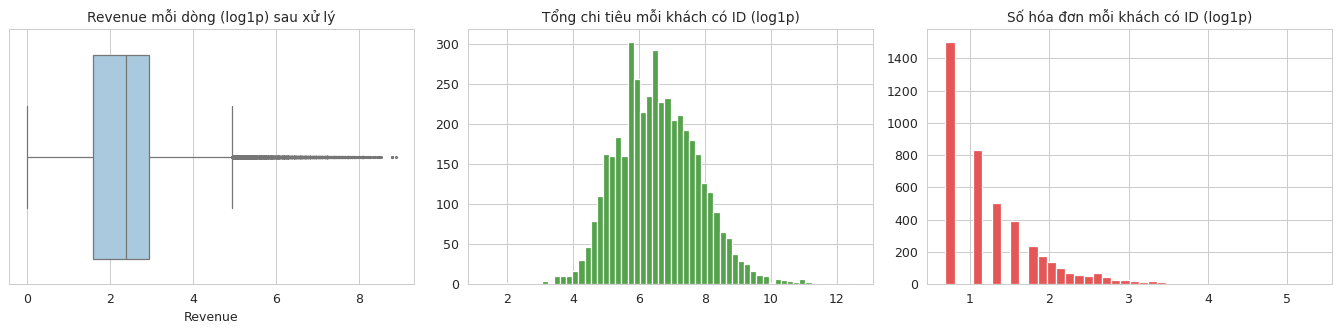

Skew cấp khách hàng (thang gốc): {'n_invoice': 11.95, 'spend': 21.04} | sau log1p: {'n_invoice': 1.21, 'spend': 0.35}


In [ ]:
reg_c = clean[~clean["IsGuest"]]
cust = reg_c.groupby("Customer ID").agg(n_invoice=("Invoice", "nunique"), spend=("Revenue", "sum"))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.boxplot(x=np.log1p(clean["Revenue"]), ax=axes[0], fliersize=1.5, color="#A0CBE8"); axes[0].set_title("Revenue mỗi dòng (log1p) sau xử lý")
axes[1].hist(np.log1p(cust["spend"]), bins=60, color="#54A24B"); axes[1].set_title("Tổng chi tiêu mỗi khách có ID (log1p)")
axes[2].hist(np.log1p(cust["n_invoice"]), bins=40, color="#E45756"); axes[2].set_title("Số hóa đơn mỗi khách có ID (log1p)")
plt.tight_layout(); plt.show()
print("Skew cấp khách hàng (thang gốc):", cust.skew().round(2).to_dict(), "| sau log1p:", np.log1p(cust).skew().round(2).to_dict())

In [ ]:
pp.save_processed(clean, log_df, ROOT / "data" / "processed")
for name in ("data_clean.csv.gz", "cleaning_log.csv"):
    f = ROOT / "data" / "processed" / name
    print(f"{f.name:22s} {f.stat().st_size/1e6:8.2f} MB")

chk = pd.read_csv(ROOT / "data" / "processed" / "data_clean.csv.gz", parse_dates=["InvoiceDate"], dtype={"Customer ID": str})
print("Đọc lại:", chk.shape, "| khớp số dòng:", len(chk) == len(clean), "| Revenue khớp:", np.isclose(chk["Revenue"].sum(), clean["Revenue"].sum()))

data_clean.csv.gz          8.54 MB
cleaning_log.csv           0.00 MB


Đọc lại: (522388, 10) | khớp số dòng: True | Revenue khớp: True
